c:\Users\Mary\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


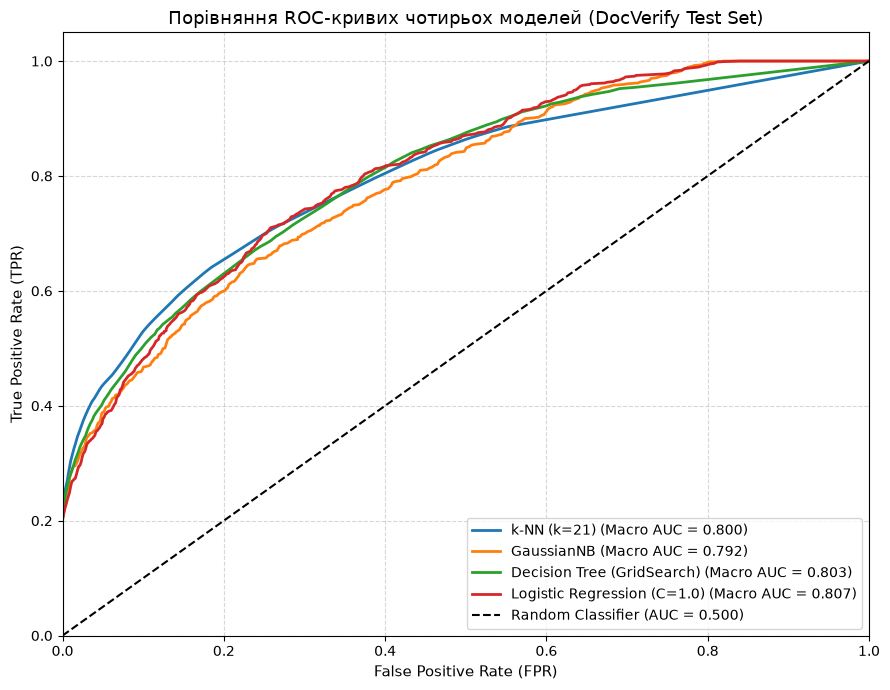

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder, label_binarize
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, auc

# ==========================================
# 1. Відтворення пайплайну підготовки даних (з Лаб. №2-6)
# ==========================================
FEATURES_CSV = "data/features_lab2.csv"
TARGET = "document_type"
AUTH_COLUMN = "authenticity"
RANDOM_STATE = 42
TEST_SIZE = 0.2

df = pd.read_csv(FEATURES_CSV)
df[AUTH_COLUMN] = df[AUTH_COLUMN].fillna('not_applicable')

# Capping викидів
for col in ['width', 'file_size_bytes']:
    q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    iqr = q3 - q1
    df[col] = df[col].clip(lower=q1 - 1.5*iqr, upper=q3 + 1.5*iqr)

if 'mean_brightness' in df.columns:
    df = df.drop(columns=['mean_brightness'])

NUMERIC_COLS_SELECTED = ['width', 'height', 'file_size_bytes', 'aspect_ratio', 'std_brightness', 'dark_pixel_ratio']
CATEGORICAL_COLS = ['source_dataset', AUTH_COLUMN]

le_target = LabelEncoder()
y = le_target.fit_transform(df[TARGET])

train_idx, test_idx = train_test_split(df.index, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y)
df_train, df_test = df.loc[train_idx], df.loc[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
ohe.fit(df_train[CATEGORICAL_COLS])
X_train_cat = ohe.transform(df_train[CATEGORICAL_COLS])
X_test_cat = ohe.transform(df_test[CATEGORICAL_COLS])

scaler = StandardScaler()
scaler.fit(df_train[NUMERIC_COLS_SELECTED])
X_train_num = scaler.transform(df_train[NUMERIC_COLS_SELECTED])
X_test_num = scaler.transform(df_test[NUMERIC_COLS_SELECTED])

X_train_processed = np.hstack([X_train_num, X_train_cat])
X_test_processed = np.hstack([X_test_num, X_test_cat])

# ==========================================
# 2. Побудова ROC-кривих (OvR) для 4 моделей
# ==========================================
n_classes = len(np.unique(y_test))
y_test_bin = label_binarize(y_test, classes=np.arange(n_classes))

models = {
    'k-NN (k=21)': KNeighborsClassifier(n_neighbors=21, metric='euclidean', weights='uniform'),
    'GaussianNB': GaussianNB(),
    'Decision Tree (GridSearch)': DecisionTreeClassifier(max_depth=10, min_samples_leaf=10, random_state=RANDOM_STATE),
    'Logistic Regression (C=1.0)': LogisticRegression(C=1.0, penalty='l2', solver='lbfgs', max_iter=1000, random_state=RANDOM_STATE)
}

plt.figure(figsize=(9, 7))
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']

for (name, model), color in zip(models.items(), colors):
    model.fit(X_train_processed, y_train)
    
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test_processed)
    else:
        y_score = model.decision_function(X_test_processed)
        
    fpr = dict()
    tpr = dict()
    all_fpr = np.unique(np.concatenate([roc_curve(y_test_bin[:, i], y_score[:, i])[0] for i in range(n_classes)]))
    mean_tpr = np.zeros_like(all_fpr)
    
    for i in range(n_classes):
        fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
        mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])
        
    mean_tpr /= n_classes
    macro_auc = auc(all_fpr, mean_tpr)
    
    plt.plot(all_fpr, mean_tpr, color=color, lw=2,
             label=f'{name} (Macro AUC = {macro_auc:.3f})')

plt.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Classifier (AUC = 0.500)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)', fontsize=11)
plt.ylabel('True Positive Rate (TPR)', fontsize=11)
plt.title('Порівняння ROC-кривих чотирьох моделей (DocVerify Test Set)', fontsize=13)
plt.legend(loc="lower right", fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

plt.savefig("outputs/fig_lab_roc_curves_comparison.png", dpi=150)
plt.show()

,Модель / Алгоритм,Середня CV Accuracy (mean),Std (std),Min,Max
0,k-NN (k=21),0.3786,0.0084,0.3684,0.3939
1,GaussianNB,0.3229,0.0064,0.3124,0.3311
2,Decision Tree (GridSearch),0.3542,0.0149,0.3362,0.3769
3,Logistic Regression (C=1.0),0.3396,0.0183,0.3175,0.3718


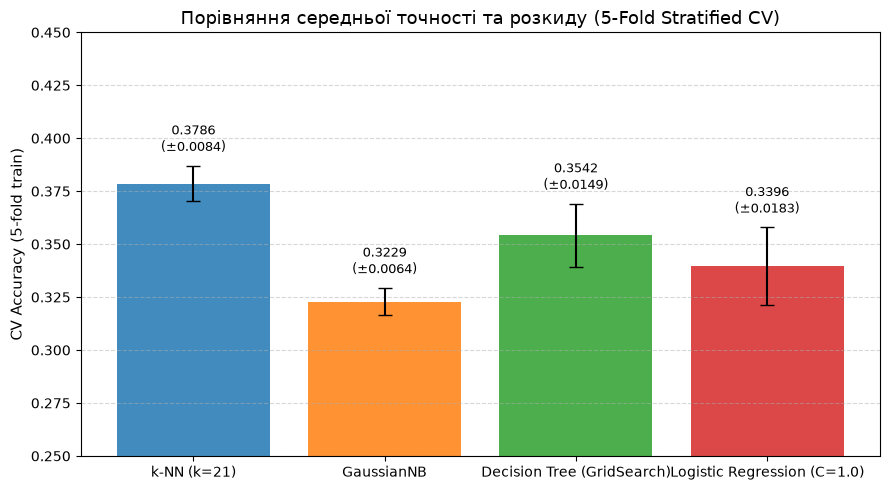

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression

# 1. Ініціалізація моделей
models = {
    'k-NN (k=21)': KNeighborsClassifier(n_neighbors=21, metric='euclidean', weights='uniform'),
    'GaussianNB': GaussianNB(),
    'Decision Tree (GridSearch)': DecisionTreeClassifier(max_depth=10, min_samples_leaf=10, random_state=42),
    'Logistic Regression (C=1.0)': LogisticRegression(C=1.0, penalty='l2', solver='lbfgs', max_iter=1000, random_state=42)
}

# 2. Налаштування 5-Fold Stratified Cross-Validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_results = {}
for name, model in models.items():
    scores = cross_val_score(model, X_train_processed, y_train, cv=cv, scoring='accuracy', n_jobs=-1)
    cv_results[name] = scores

# 3. Формування підсумкової таблиці
summary_data = []
for name, scores in cv_results.items():
    summary_data.append({
        'Модель / Алгоритм': name,
        'Середня CV Accuracy (mean)': round(np.mean(scores), 4),
        'Std (std)': round(np.std(scores), 4),
        'Min': round(np.min(scores), 4),
        'Max': round(np.max(scores), 4)
    })

df_cv_summary = pd.DataFrame(summary_data)
display(df_cv_summary)

# 4. Побудова графіку порівняння (Boxplot / Barplot з помилками)
plt.figure(figsize=(9, 5))
means = df_cv_summary['Середня CV Accuracy (mean)']
stds = df_cv_summary['Std (std)']
names = df_cv_summary['Модель / Алгоритм']

bars = plt.bar(names, means, yerr=stds, capsize=5, color=['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728'], alpha=0.85)
plt.ylabel('CV Accuracy (5-fold train)', fontsize=11)
plt.title('Порівняння середньої точності та розкиду (5-Fold Stratified CV)', fontsize=13)
plt.ylim([0.25, 0.45])
plt.grid(True, linestyle='--', alpha=0.5, axis='y')

# Додавання числових підписів над стовпчиками
for bar, mean, std in zip(bars, means, stds):
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + std + 0.005, f'{mean:.4f}\n(±{std:.4f})', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.savefig("outputs/fig_lab_cv_comparison.png", dpi=150)
plt.show()